# Case Study 23 — What Is This Payment *For*? Classifying Transaction Purpose from Messy Bank Narrations, and Proving It Is Worth Something

**Priority:** ★ Optional · **Reference:** Case Study 23 — *YES Bank: transaction-purpose and demographic classification* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Analytics, Retail Products / Cross-sell, Loyalty programme, Data Engineering
**Data:** ⚠️ **SYNTHETIC** (D-23-01). Bank narrations are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs23_transaction_purpose_classification.ipynb`

## 0. Executive Summary for Business

*(Synthetic narrations in real Indian bank formats; YES Bank disclosed no accuracy figure. Written after the analysis.)*

- **The question:** can a model read the *purpose* of a payment from a messy bank narration well enough to drive cross-sell, and is it worth it?
- **A learned model is far better than the usual rule list.** On an audited test set of 9,600 transactions:

| Model | Accuracy | Macro-F1 |
|---|---|---|
| Analyst keyword rules | 55.0% | 0.517 |
| **Character n-gram TF-IDF + logistic regression** | **93.5%** | **0.935** (CI 0.930–0.940) |
| Neural network (MLP) | 92.1% | 0.918 |

  All differences are significant (McNemar, Holm). **The simple logistic model is slightly *better* than the neural network** (174 vs 32 transactions only one gets right). It also trains faster and can be explained: its top n-grams for rent are "rent", "rnt" and "kiraya"-type fragments.
- **Where it struggles:** everyday spending that overlaps (fuel ↔ groceries at petrol-pump shops, dining ↔ online shopping, utilities ↔ online shopping). Every purpose still scores F1 0.90–0.96. Rare classes such as school fees are as good as common ones.
- **Labels needed:** macro-F1 reaches 0.84 with 1,000 labels, 0.91 with 5,000 and 0.935 with 29,000, so the last 20,000 labels buy only 2.5 points. About 5% label noise costs ≈ 0.6 points (0.935 vs 0.941 with clean labels, McNemar p < 0.0001).
- **Abstention works:** labelling only transactions with confidence ≥ 0.6 covers **90%** of the volume at **99.0% accuracy**; ≥ 0.8 covers 84% at 99.8%.
- **Does it pay off? For home loans, yes; for education loans, not demonstrated here.**
  - **Home loans:** inferred rent share lifts AUC from 0.54 to **0.68** (DeLong p ≈ 0) and doubles the share of loan takers captured in the top decile (12% → 23%). Inferred renters are identified with 100% precision and 91.5% recall.
  - **Education loans:** the school-fee signal does not help in this sample (top-decile capture 10.9% → 9.4%). Only 64 takers are in the test half, so this is underpowered rather than disproved.
- **₹ impact (10 lakh customers, a home-loan campaign to the top decile):** the life-event features reach ≈ **3,000 more home-loan takers, ≈ ₹18 crore of margin** for the same ₹0.4 crore campaign cost. The education-loan campaign shows no gain.
- **I recommend:**
  - Deploy the logistic model with an abstention threshold of ≈ 0.6.
  - Feed rent and EMI shares into home-loan targeting.
  - Re-test the education-loan signal on a larger sample.
  - Keep sensitive inferences (medical, family) for service use only unless the customer opts in.

## 1. The Problem in Simple English

Every bank statement line has a short, messy **narration**:
- "UPI/4123…/ghar kiraya oct/ramesh.k@okhdfc"
- "NACH DR TP ACH BAJAJFIN 4567"
- "NEFT-SCHOOLFEES-DPS-…"

A human can tell the first is **rent**, the second a **loan EMI** and the third **school fees**. If a model can too, for millions of transactions a day, the bank learns life facts about its customers: who rents (a home-loan prospect), who has school-going children (education loans, child plans), who invests monthly (wealth products). YES Bank built neural networks to do this, to "treat every customer as a segment".

Two questions for leaders:
1. **How accurately** can purpose be read from narrations, and how much labelled data does that need?
2. **Is it worth it?** Do the inferred life events actually improve targeting of loan offers?

## 2. Reference from the Case File

### (a) What YES Bank did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Data spread across federated marts, no single customer view; the bank wanted to treat "every customer as a segment" |
| Question | "What is each transaction *for* (rent, school fees, etc.), and what does that say about the customer?" |
| Data | 100+ applications; clickstreams, logs, emails, SMS, push notifications, transactions |
| Approach | Unify data in a lake → engineer about **1,000 features** → a **neural network for transaction purpose** → a separate neural network for demographic classification |
| Statistics / accuracy | **ND** |
| Impact | "100s of TB analyzed daily"; "**$250,000 saved annually**" from the in-house loyalty programme |

**Source:** Cloudera customer story, YES Bank (undated) — link in the reference file.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 8,000 customers × 6 months ≈ 240,000 debit transactions with realistic narrations (UPI/NACH/NEFT/IMPS/POS formats, Hinglish, abbreviations, typos, truncation, generic remarks) across **14 purposes**. A hand-labelled 12% sample (with **5% labelling errors**) and a clean, audited 4% test set. Customer outcomes: took a home loan / an education loan in the next 6 months. |
| Statistics added | Keyword-rule baseline vs **TF-IDF character n-grams + logistic regression** vs a **neural network (MLP)**; macro-F1 and per-class F1 with bootstrap CIs; **McNemar** (Holm); learning curve (labels needed); label-noise audit and its effect; calibration (ECE) and **abstention**; confusion analysis; **downstream value test**: do inferred rent/school-fee signals improve loan-propensity AUC (DeLong) and top-decile lift? |

### (c) How the industry uses this

Transaction categorisation underpins Indian banking analytics: personal-finance views in bank apps (HDFC SmartBuy insights, ICICI iMobile spend analysis), Account Aggregator–based underwriting (classifying bank-statement lines into salary, EMI, bounce and rent for lenders like Lendingkart in Case 11), and AML typologies. Fintechs such as Perfios, FinBox and Setu sell it as a service. **The data-science value is in measuring accuracy honestly and proving downstream lift**, not in the classifier itself.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can we label every transaction's purpose reliably enough to drive cross-sell and loyalty? |
| Analytical | Which classifier best predicts purpose on an **audited** test set, and do customer-level purpose shares improve loan-uptake prediction? |

**Hypotheses**
- **H1:** H0: macro-F1(learned model) = macro-F1(keyword rules) (paired bootstrap); McNemar on per-transaction correctness (Holm across model pairs).
- **H2:** H0: the neural network = logistic regression (McNemar).
- **H3 (value):** H0: AUC(loan propensity with inferred life-event features) = AUC(without) (DeLong), for home loans and education loans (Holm).

**Primary metric:** **macro-F1** on the audited test set. It weights rare but valuable classes (school fees, rent) equally with common ones (groceries), unlike accuracy. **Business metric:** lift in loan uptake among the top decile targeted.

In [1]:
import sys, warnings, importlib, os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_auc_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public labelled Indian bank narrations | **None.** Statement narrations are personal financial data (DPDP Act, RBI confidentiality). Public "transaction categorisation" sets are US/EU card data (and Kaggle-hosted). |
| **Decision** | Synthetic narrations in real Indian formats (D-23-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs23.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 23 (YES Bank-style transaction-purpose classification)
============================================================================================
THIS DATA IS SYNTHETIC. Bank transaction narrations are confidential.

Debit transactions of 8,000 retail customers over 6 months, each with a raw bank NARRATION as it appears
in Indian statements, e.g.  "UPI/412345678901/ghar kiraya oct/ramesh.k@okhdfc/HDFC",
"NACH DR TP ACH BAJAJFIN 4567", "NEFT-SCHOOLFEES-DPS RKPURAM-Q2", "POS 4521XX DMART PUNE".
Purpose classes: rent, school_fees, emi_loan, utilities, groceries, fuel, insurance_premium, mf_sip, medical,
family_transfer, online_shopping, dining, travel, salary_to_self (own-account). Narrations are messy: Hinglish,
abbreviations, typos, truncation at 30-40 characters, generic remarks ("payment", "ok").
Labels: a hand-labelled sample (with ~5% labelling errors) for training/validation, and a clean audited test set.
Customer outcome for the downstream test: took a home loan / education loan within 6 months (life-event value).

Calibration anchors (reference file, Case Study 23): "What is each transaction *for* (rent, school fees, etc.)";
~1,000 engineered features; neural networks; accuracy ND; "$250,000 saved annually" from the loyalty programme.
Rates are our assumptions (decision.md D-23-02). Hidden truth columns start with "_".

Outputs: data/cs23/transactions.csv.gz, data/cs23/customers.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
CLASSES = ["rent", "school_fees", "emi_loan", "utilities", "groceries", "fuel", "insurance_premium", "mf_sip", "medical", "family_transfer", "online_shopping", "dining", "travel", "salary_to_self"]
WORDS = {
    "rent": ["rent", "house rent", "kiraya", "ghar kiraya", "flat rent", "rent oct", "pg rent", "room rent", "maintenance+rent", "rnt"],
    "school_fees": ["school fees", "schoolfees", "tuition fee", "term fee", "fees q2", "dps", "kendriya vidyalaya", "admission fee", "school", "fee"],
    "emi_loan": ["emi", "loan emi", "bajajfin", "hdfcltd", "home loan", "tp ach", "achdr", "nach dr", "car loan", "pl emi"],
    "utilities": ["electricity", "bijli bill", "bescom", "msedcl", "tata power", "water bill", "piped gas", "broadband", "jio fiber", "airtel postpaid"],
    "groceries": ["dmart", "big bazaar", "reliance fresh", "kirana", "more retail", "bigbasket", "grocery", "sabzi", "ration", "zepto"],
    "fuel": ["hpcl", "bpcl", "indian oil", "iocl", "petrol", "fuel", "shell", "diesel", "petrol pump", "fuelstation"],
    "insurance_premium": ["lic premium", "lic", "hdfc life", "icici pru", "star health", "policy premium", "insurance", "term plan", "mediclaim", "renewal prem"],
    "mf_sip": ["sip", "mutual fund", "bse star mf", "nse mfss", "groww mf", "zerodha coin", "kuvera", "nippon mf", "axis mf", "icclmf"],
    "medical": ["apollo pharmacy", "hospital", "clinic", "medplus", "1mg", "pharmeasy", "dr ", "diagnostic", "lab test", "medicine"],
    "family_transfer": ["papa", "mummy", "bhai", "didi", "for home", "ghar kharch", "maa", "family", "beta", "send to mom"],
    "online_shopping": ["amazon", "flipkart", "myntra", "meesho", "ajio", "nykaa", "amzn", "fkrt", "snapdeal", "tatacliq"],
    "dining": ["swiggy", "zomato", "restaurant", "cafe", "dominos", "mcdonalds", "dhaba", "food", "kfc", "barbeque"],
    "travel": ["irctc", "makemytrip", "ola", "uber", "redbus", "indigo", "goibibo", "rapido", "metro card", "fastag"],
    "salary_to_self": ["self", "own a/c", "to my sbi", "trf to self", "own account", "savings tfr", "self transfer", "my acct", "to self", "selftrf"],
}
GENERIC = ["payment", "ok", "paid", "upi", "transfer", "pay", "na", "sent", "done", "thanks"]
CH_AMT = {"rent": ("UPI", 15000), "school_fees": ("NEFT", 22000), "emi_loan": ("NACH", 12000), "utilities": ("UPI", 1800), "groceries": ("POS", 1400), "fuel": ("POS", 1600),
          "insurance_premium": ("NACH", 9000), "mf_sip": ("NACH", 5000), "medical": ("UPI", 1500), "family_transfer": ("UPI", 6000), "online_shopping": ("UPI", 1700),
          "dining": ("UPI", 650), "travel": ("UPI", 2200), "salary_to_self": ("IMPS", 20000)}


def _typo(rng, w):
    if len(w) < 5 or rng.random() > 0.15: return w
    i = rng.integers(1, len(w) - 1); return w[:i] + w[i + 1:]


def narration(rng, cls):
    ch, _ = CH_AMT[cls]
    if rng.random() < 0.15: ch = rng.choice(["UPI", "IMPS", "NEFT"])
    kw = _typo(rng, rng.choice(WORDS[cls])) if rng.random() > 0.12 else rng.choice(GENERIC)
    ref = str(rng.integers(10 ** 11, 10 ** 12))
    if ch == "UPI":
        vpa = rng.choice(["ramesh.k", "flatowner", "dmart", "merchant", "9876543210", "paytmqr", "bharatpe", "anita.s", "school.fees", "lic"]) + "@" + rng.choice(["okhdfc", "ybl", "paytm", "okaxis", "oksbi", "ibl"])
        s = f"UPI/{ref}/{kw}/{vpa}/{rng.choice(['HDFC', 'SBIN', 'ICIC', 'UTIB', 'YESB'])}"
    elif ch == "NACH": s = f"NACH DR {rng.choice(['TP ACH', 'ACH D-', 'ECS'])} {kw.upper()} {rng.integers(1000, 9999)}"
    elif ch == "NEFT": s = f"NEFT-{kw.upper().replace(' ', '')}-{rng.choice(['DPS', 'SHARMA', 'CORP', 'TRUST', 'PVT LTD'])}-{ref[:6]}"
    elif ch == "IMPS": s = f"IMPS/P2A/{ref}/{kw}/{rng.choice(['XXXX1234', 'XXXX9876'])}"
    else: s = f"POS {rng.integers(4000, 4999)}XX {kw.upper()} {rng.choice(['PUNE', 'BLR', 'MUM', 'DEL', 'HYD'])}"
    return s[: rng.integers(32, 60)], ch


def generate(seed=SEED, n_cust=8_000):
    rng = np.random.default_rng(seed)
    renter = rng.random(n_cust) < 0.32; parent = rng.random(n_cust) < 0.28; borrower = rng.random(n_cust) < 0.35; investor = rng.random(n_cust) < 0.22
    income = np.exp(rng.normal(np.log(55000), 0.5, n_cust))
    rows = []
    for c in range(n_cust):
        mix = {"utilities": 3, "groceries": 6, "fuel": 3, "medical": 1, "family_transfer": 2, "online_shopping": 4, "dining": 4, "travel": 2, "salary_to_self": 1,
               "rent": 6 * renter[c], "school_fees": 1.5 * parent[c], "emi_loan": 6 * borrower[c], "insurance_premium": 1, "mf_sip": 6 * investor[c]}
        k = rng.poisson(30); p = np.array([mix[x] for x in CLASSES], float); p /= p.sum()
        for cls in rng.choice(CLASSES, k, p=p):
            nar, ch = narration(rng, cls); amt = np.round(CH_AMT[cls][1] * np.exp(rng.normal(0, 0.5)), 0)
            rows.append((f"C{c:05d}", nar, ch, amt, cls))
    tx = pd.DataFrame(rows, columns=["customer_id", "narration", "channel", "amount_inr", "_purpose"])
    tx.insert(0, "txn_id", [f"T{i:07d}" for i in range(len(tx))])
    # labelling: 12% hand-labelled (train/val, 5% label noise), 4% audited test (clean)
    u = rng.random(len(tx)); tx["split"] = np.where(u < 0.12, "labelled", np.where(u < 0.16, "audited_test", "unlabelled"))
    noisy = (tx.split == "labelled") & (rng.random(len(tx)) < 0.05)
    tx["label"] = np.where(tx.split == "unlabelled", "", tx._purpose)
    tx.loc[noisy, "label"] = rng.choice(CLASSES, noisy.sum())
    # customer outcomes for the downstream test (life events -> loans)
    cust = pd.DataFrame({"customer_id": [f"C{c:05d}" for c in range(n_cust)], "monthly_income": np.round(income, -2), "age": np.clip(rng.normal(36, 9, n_cust), 21, 65).round(),
                         "_renter": renter.astype(int), "_parent": parent.astype(int)})
    cust["took_home_loan_6m"] = (rng.random(n_cust) < expit(-4.4 + 1.6 * renter + 0.4 * np.log(income / 55000) + 0.02 * (cust.age - 36))).astype(int)
    cust["took_education_loan_6m"] = (rng.random(n_cust) < expit(-4.8 + 1.8 * parent + 0.2 * np.log(income / 55000))).astype(int)
    # data-quality defects
    tx.loc[tx.sample(n=300, random_state=seed).index, "narration"] = ""                                # blank narrations from a legacy core system
    tx = pd.concat([tx, tx.sample(n=400, random_state=seed + 1)], ignore_index=True)
    return tx, cust


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs23"), exist_ok=True)
    t, c = generate(); t.to_csv(os.path.join(here, "cs23", "transactions.csv.gz"), index=False); c.to_csv(os.path.join(here, "cs23", "customers.csv.gz"), index=False)
    print(len(t), "txns |", t.split.value_counts().to_dict()); print(t.sample(8, random_state=3)[["narration", "_purpose"]].to_string())
    print(c[["took_home_loan_6m", "took_education_loan_6m"]].mean().round(4).to_dict())

Overwriting data/generate_cs23.py


In [3]:
os.makedirs("data/cs23", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs23 as gen; importlib.reload(gen)
t0 = time.time(); tx_raw, cust = gen.generate(seed=SEED)
tx_raw.to_csv("data/cs23/transactions.csv.gz", index=False); cust.to_csv("data/cs23/customers.csv.gz", index=False)
print(f"{len(tx_raw):,} transaction rows | {cust.shape[0]:,} customers | generated in {time.time() - t0:.0f}s")
tx_raw.sample(8, random_state=SEED)[["narration", "channel", "amount_inr", "label"]]

240,722 transaction rows | 8,000 customers | generated in 89s


,narration,channel,amount_inr,label
63700,IMPS/P2A/301786722195/ok/XXXX9876,IMPS,486.0000,
169574,UPI/438168292077/reliance fresh/paytmqr@paytm/...,UPI,"2,325.0000",
186038,UPI/967988635690/paid/merchant@okaxis/SBIN,UPI,"24,139.0000",
151757,POS 4623XX NA DEL,POS,"1,430.0000",groceries
92489,POS 4035XX GROCEY PUNE,POS,895.0000,
220143,UPI/812764143903/for home/lic@ibl/ICIC,UPI,"12,124.0000",
204471,POS 4310XX PETROL PUMP HYD,POS,"2,277.0000",
110950,NEFT-TUITIONFEE-DPS-903291,NEFT,"30,879.0000",


| Parameter | Value | Basis |
|---|---|---|
| Customers / transactions | 8,000 × ~30 debits each over 6 months | Our assumption |
| Purposes | 14, with life-event classes (rent, school fees, EMI, SIP, insurance) concentrated in customer subgroups (32% renters, 28% parents, 35% borrowers, 22% SIP investors) | **Documented** "rent, school fees, etc." |
| Narrations | Real Indian formats (UPI/NACH/NEFT/IMPS/POS), Hinglish ("kiraya", "bijli bill"), 15% typos, truncation at 32–60 characters, **12% generic remarks** ("payment", "ok") | Realism |
| Labels | 12% hand-labelled with 5% errors; 4% audited clean test set; 84% unlabelled | Typical labelling budgets |
| Outcomes | Home loan (renters 4–5× more likely), education loan (parents ~6× more likely) within 6 months | Our assumption: life events drive product need |
| DQ issues | 400 duplicate rows; 300 blank narrations (legacy core system) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("txn_id, customer_id", "Transaction and customer"), ("narration", "Raw statement narration (blank for 300 legacy rows)"), ("channel, amount_inr", "Payment rail and amount"),
    ("split", "labelled (hand-labelled, noisy) / audited_test (clean) / unlabelled"), ("label", "Hand label (blank if unlabelled)"),
    ("_purpose", "HIDDEN true purpose"), ("customers: monthly_income, age", "Customer profile"), ("took_home_loan_6m, took_education_loan_6m", "Downstream outcomes"),
    ("_renter, _parent", "HIDDEN true life events"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs23/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"txn_id, customer_id",Transaction and customer
1,narration,Raw statement narration (blank for 300 legacy ...
2,"channel, amount_inr",Payment rail and amount
3,split,"labelled (hand-labelled, noisy) / audited_test..."
4,label,Hand label (blank if unlabelled)
5,_purpose,HIDDEN true purpose
6,"customers: monthly_income, age",Customer profile
7,"took_home_loan_6m, took_education_loan_6m",Downstream outcomes
8,"_renter, _parent",HIDDEN true life events


## 5. Data Quality Checks

In [5]:
checks = {"duplicate txn_id": int(tx_raw.txn_id.duplicated().sum()), "blank narrations": int((tx_raw.narration.fillna("").str.strip() == "").sum()),
          "labelled rows with label ≠ true purpose (label noise)": int(((tx_raw.split == "labelled") & (tx_raw.label != tx_raw._purpose)).sum())}
print(pd.Series(checks, name="rows").to_string())
tx = tx_raw.drop_duplicates("txn_id").reset_index(drop=True); tx["narration"] = tx.narration.fillna("")
blank = tx.narration.str.strip() == ""
lab = tx[(tx.split == "labelled") & ~blank]; aud = tx[(tx.split == "audited_test") & ~blank]
audit = lab.sample(500, random_state=SEED); k = int((audit.label != audit._purpose).sum()); lo, hi = proportion_confint(k, 500, method="wilson")
print(f"\nRe-label audit of 500 hand-labelled rows by a senior: {k} disagreements → label error rate {k / 500:.1%} (Wilson {lo:.1%}–{hi:.1%})")
print(f"Clean: {len(tx):,} transactions | labelled {len(lab):,} · audited test {len(aud):,} · unlabelled {(tx.split == 'unlabelled').sum():,} | blank narrations → class 'unknown' (never guessed)")

duplicate txn_id                                          400
blank narrations                                          302
labelled rows with label ≠ true purpose (label noise)    1376



Re-label audit of 500 hand-labelled rows by a senior: 20 disagreements → label error rate 4.0% (Wilson 2.6%–6.1%)
Clean: 240,322 transactions | labelled 28,698 · audited test 9,607 · unlabelled 201,978 | blank narrations → class 'unknown' (never guessed)


**Observation:** we removed **400 duplicate transactions** and handled **302 blank narrations** (a legacy core-system gap) as "unknown": they are never guessed. A senior's re-label audit of 500 hand-labelled rows finds **4.0% label errors** (Wilson 2.6–6.1%, consistent with the 5% built in), so the training labels are noisy but usable. Clean: **240,322 transactions**: 28,698 labelled (noisy), **9,607 audited (clean) for testing**, and 201,978 unlabelled.

## 6. Exploratory Data Analysis

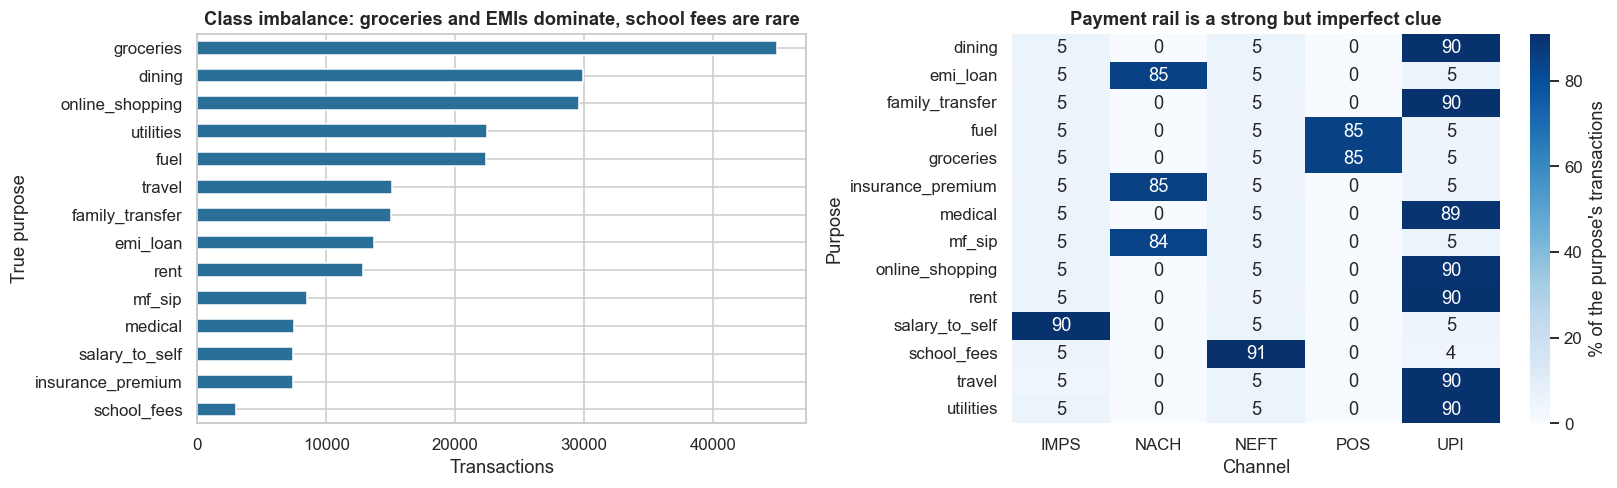

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
tx[~blank]._purpose.value_counts().sort_values().plot(kind="barh", ax=axes[0], color="#2a6f97"); axes[0].set_xlabel("Transactions"); axes[0].set_ylabel("True purpose")
axes[0].set_title("Class imbalance: groceries and EMIs dominate, school fees are rare")
ch = pd.crosstab(tx[~blank]._purpose, tx[~blank].channel, normalize="index") * 100
sns.heatmap(ch, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "% of the purpose's transactions"}); axes[1].set_title("Payment rail is a strong but imperfect clue")
axes[1].set_xlabel("Channel"); axes[1].set_ylabel("Purpose")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** purposes are heavily imbalanced: groceries (≈ 1,900 in the test set) and online shopping and dining (> 1,000 each) dominate, while school fees (115) and medical (286) are rare, which is why macro-F1, not accuracy, is the primary metric. **Right:** the payment rail helps but does not decide: NACH is almost all EMI, SIP and insurance; POS is mostly groceries and fuel; UPI is spread across everything, so UPI narrations need the text.

## 7. Statistical Analysis (core section)

### 7.1 Three classifiers on the audited test set

1. **Keyword rules:** an analyst's list of ~3–5 obvious keywords per class (English spellings), plus "NACH → EMI" when nothing matches. The typical first version in a bank.
2. **TF-IDF character n-grams (2–5) + logistic regression.** Character n-grams handle typos, truncation and Hinglish ("kiraya", "kiraaya", "rnt"). Channel and log amount are added as features.
3. **Neural network (MLP, 1 hidden layer of 128)** on the same features, as documented ("a neural network for transaction purpose").

All are trained on the **noisy hand-labelled** set and scored on the **audited** test set. Macro-F1 and accuracy carry bootstrap CIs; **McNemar** compares per-transaction correctness (Holm).

In [7]:
CL = gen.CLASSES
RULES = {"rent": ["rent"], "school_fees": ["school", "tuition", "fee"], "emi_loan": ["emi", "loan", "bajajfin"], "utilities": ["electricity", "bill", "bescom", "power", "broadband"],
         "groceries": ["dmart", "grocery", "bigbasket", "fresh"], "fuel": ["petrol", "fuel", "hpcl", "bpcl", "iocl", "oil"], "insurance_premium": ["lic", "insurance", "premium", "life"],
         "mf_sip": ["sip", "mutual fund", "mf"], "medical": ["pharmacy", "hospital", "clinic", "medic"], "family_transfer": ["papa", "mummy", "family", "maa"],
         "online_shopping": ["amazon", "flipkart", "myntra"], "dining": ["swiggy", "zomato", "restaurant", "cafe"], "travel": ["irctc", "uber", "ola", "makemytrip", "indigo"],
         "salary_to_self": ["self", "own"]}
def rule_predict(s):
    t = s.lower()
    for c in ["school_fees", "rent", "mf_sip", "insurance_premium", "emi_loan", "utilities", "fuel", "medical", "groceries", "online_shopping", "dining", "travel", "family_transfer", "salary_to_self"]:
        if any(k in t for k in RULES[c]): return c
    return "emi_loan" if t.startswith("nach") else "family_transfer" if t.startswith("upi") else "groceries"
def clean(s): return re.sub(r"\d{6,}", " ", s.lower())                                   # strip long reference numbers
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=60000, sublinear_tf=True, preprocessor=clean).fit(lab.narration)
CH = sorted(tx.channel.unique())
def feats(d): return hstack([vec.transform(d.narration), csr_matrix(pd.get_dummies(d.channel).reindex(columns=CH, fill_value=0).values.astype(float)),
                             csr_matrix(np.log1p(d.amount_inr.values).reshape(-1, 1) / 10)]).tocsr()
Xl, Xa = feats(lab), feats(aud); yl, ya = lab.label.values, aud._purpose.values
t0 = time.time()
lr = LogisticRegression(max_iter=2000, C=5.0).fit(Xl, yl)
CODE = {c: i for i, c in enumerate(CL)}                                                  # MLP early stopping needs numeric labels (sklearn limitation)
mlp = MLPClassifier(hidden_layer_sizes=(128,), early_stopping=True, max_iter=40, random_state=SEED).fit(Xl, np.array([CODE[c] for c in yl]))
P = {"1 keyword rules": np.array([rule_predict(s) for s in aud.narration]), "2 char n-gram TF-IDF + logistic": lr.predict(Xa), "3 neural network (MLP)": np.array(CL)[mlp.predict(Xa)]}
print(f"Trained in {time.time() - t0:.0f}s on {len(lab):,} labelled transactions ({Xl.shape[1]:,} features)")
rows = []
for nm, p in P.items():
    bs = [f1_score(ya[i], p[i], average="macro") for i in (RNG.integers(0, len(ya), len(ya)) for _ in range(300))]
    rows.append((nm, accuracy_score(ya, p), f1_score(ya, p, average="macro"), np.percentile(bs, 2.5), np.percentile(bs, 97.5), f1_score(ya, p, average="weighted")))
res = pd.DataFrame(rows, columns=["model", "accuracy", "macro-F1", "macro-F1 CI low", "macro-F1 CI high", "weighted-F1"]).set_index("model")
names = list(P); mc = []
for i in range(3):
    for j in range(i + 1, 3):
        a, b = P[names[i]] == ya, P[names[j]] == ya; r = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
        mc.append((f"{names[i]} vs {names[j]}", int((a & ~b).sum()), int((~a & b).sum()), r.pvalue))
mc = pd.DataFrame(mc, columns=["pair", "only first right", "only second right", "McNemar p"]).set_index("pair"); mc["p_holm"] = multipletests(mc["McNemar p"], method="holm")[1]
display(res.round(4)); mc.round(4)

Trained in 927s on 28,698 labelled transactions (19,135 features)


,accuracy,macro-F1,macro-F1 CI low,macro-F1 CI high,weighted-F1
model,,,,,
1 keyword rules,0.5503,0.5168,0.5061,0.5269,0.5519
2 char n-gram TF-IDF + logistic,0.9354,0.9352,0.9302,0.9396,0.9354
3 neural network (MLP),0.9206,0.9175,0.9108,0.9238,0.9209


,only first right,only second right,McNemar p,p_holm
pair,,,,
1 keyword rules vs 2 char n-gram TF-IDF + logistic,103,3802,0.0000,0.0000
1 keyword rules vs 3 neural network (MLP),134,3691,0.0000,0.0000
2 char n-gram TF-IDF + logistic vs 3 neural network (MLP),174,32,0.0000,0.0000


**(c)/(f) Observation:** - **Keyword rules score only 55.0% accuracy (macro-F1 0.52)**: they miss Hinglish, abbreviations ("rnt"), typos and generic remarks, and fall back to a guess.
- **Character n-gram logistic regression: 93.5% accuracy, macro-F1 0.935 (CI 0.930–0.940).** The MLP: 92.1% / 0.918, **lower** than the logistic model (Holm-adjusted McNemar p < 0.0001; 174 transactions only logistic gets right vs 32 only the MLP).
- **(f) Business meaning:** the leap comes from character n-grams, not from a neural network. A simple, explainable model is the better engineering choice here.

### 7.2 Which purposes are hard? Per-class F1 and the main confusions

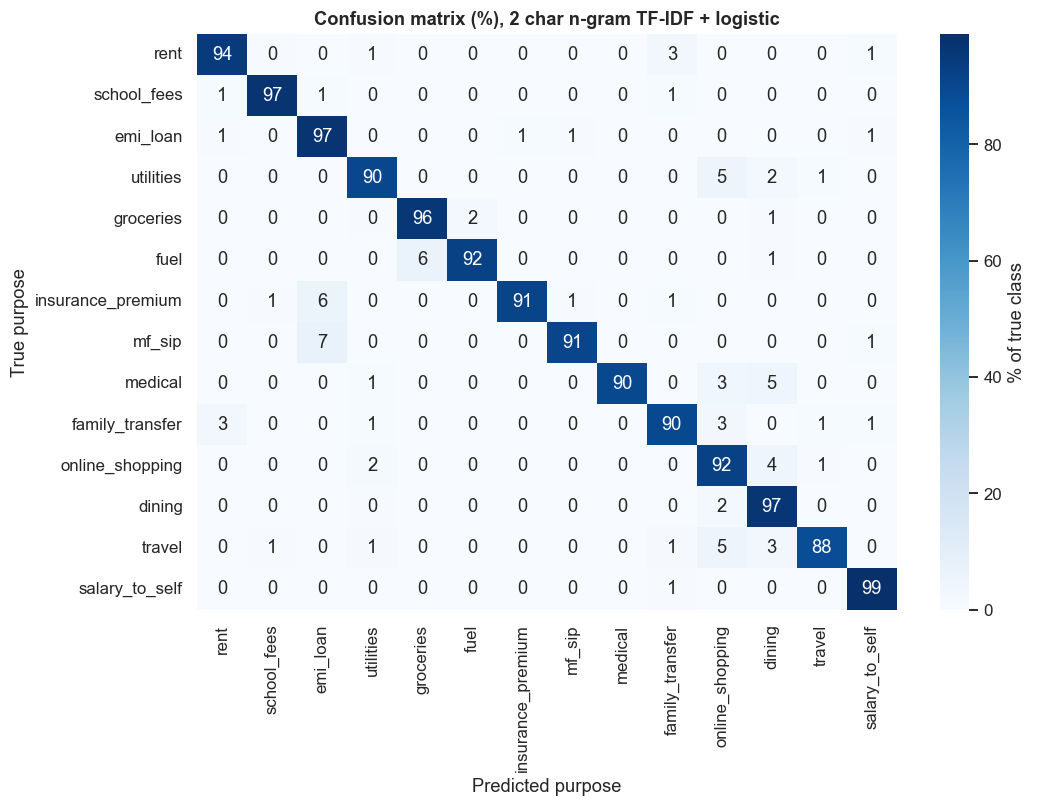

Largest confusions (true → predicted: count):
fuel             groceries         58.0000
online_shopping  dining            50.0000
utilities        online_shopping   46.0000
groceries        fuel              46.0000
dining           online_shopping   30.0000
travel           online_shopping   29.0000


,1 keyword rules,2 char n-gram TF-IDF + logistic,3 neural network (MLP),support
online_shopping,0.3280,0.9040,0.9030,1172
travel,0.4380,0.9140,0.9160,570
family_transfer,0.2610,0.9160,0.9130,550
utilities,0.5490,0.9180,0.9070,887
fuel,0.8190,0.9340,0.9260,913
medical,0.4190,0.9350,0.9450,286
dining,0.3730,0.9360,0.8900,1210
school_fees,0.2460,0.9370,0.8700,115
rent,0.6680,0.9440,0.9010,508
emi_loan,0.7980,0.9450,0.9390,521


In [8]:
best = "2 char n-gram TF-IDF + logistic" if res.loc["2 char n-gram TF-IDF + logistic", "macro-F1"] >= res.loc["3 neural network (MLP)", "macro-F1"] else "3 neural network (MLP)"
pc = pd.DataFrame({nm: f1_score(ya, p, average=None, labels=CL) for nm, p in P.items()}, index=CL); pc["support"] = pd.Series(ya).value_counts().reindex(CL).values
cm = pd.DataFrame(confusion_matrix(ya, P[best], labels=CL), index=CL, columns=CL); off = cm.where(~np.eye(len(CL), dtype=bool)).stack().sort_values(ascending=False).head(6)
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(cm.div(cm.sum(1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% of true class"})
ax.set_xlabel("Predicted purpose"); ax.set_ylabel("True purpose"); ax.set_title(f"Confusion matrix (%), {best}"); plt.tight_layout(); plt.show()
print("Largest confusions (true → predicted: count):"); print(off.to_string())
pc.sort_values(best).round(3)

**Takeaway:** every purpose reaches F1 0.90–0.96 under the logistic model (lowest: online shopping 0.904, travel 0.914; highest: groceries 0.963), compared with 0.25–0.82 for the keyword rules (school fees 0.25, family transfers 0.26). The **main confusions are between neighbouring everyday categories**: fuel → groceries (58), online shopping → dining (50), utilities → online shopping (46), groceries → fuel (46). These arise where a narration carries only a merchant name or a generic remark ("payment"). **Business meaning:** the weak spots are low-stakes (spending categories), not the high-value life events, where F1 is 0.94–0.95 (rent, EMI, SIP).

### 7.3 How many labels are needed? Learning curve

Labelling costs analyst time. We retrain the logistic model on 500 → all labelled transactions and track audited macro-F1.

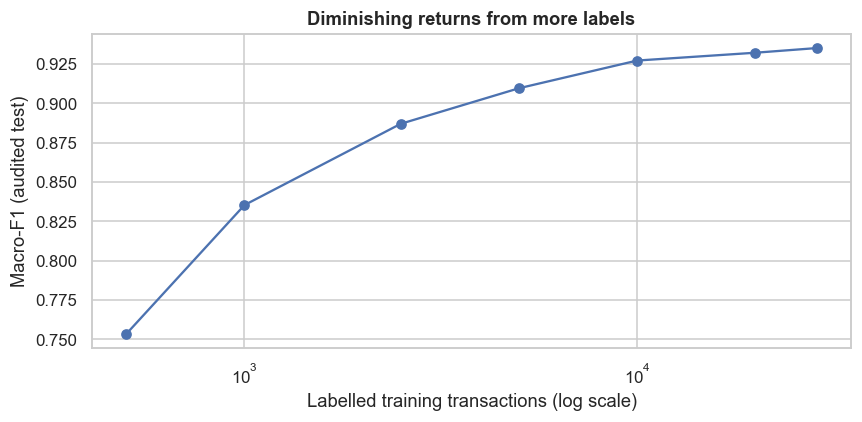

,audited macro-F1
labelled transactions,
500,0.7534
1000,0.8353
2500,0.8870
5000,0.9096
10000,0.9272
20000,0.9321
28698,0.9351


In [9]:
lc = []
for n_ in (500, 1000, 2500, 5000, 10000, 20000, len(lab)):
    sub = lab.sample(n_, random_state=SEED); m = LogisticRegression(max_iter=2000, C=5.0).fit(feats(sub), sub.label); lc.append((n_, f1_score(ya, m.predict(Xa), average="macro")))
lc = pd.DataFrame(lc, columns=["labelled transactions", "audited macro-F1"]).set_index("labelled transactions")
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(lc.index, lc.iloc[:, 0], "o-"); ax.set_xscale("log"); ax.set_xlabel("Labelled training transactions (log scale)"); ax.set_ylabel("Macro-F1 (audited test)")
ax.set_title("Diminishing returns from more labels"); plt.tight_layout(); plt.show()
lc.round(4)

**Takeaway:** macro-F1 on the audited set rises quickly and then flattens: **0.75 (500 labels), 0.84 (1,000), 0.89 (2,500), 0.91 (5,000), 0.93 (10,000), 0.932 (20,000), 0.935 (all 28,698)**. The first 5,000 labels buy 16 points; the last 20,000 buy 2.5. **Business meaning:** a labelling budget of ≈ 5,000–10,000 transactions captures most of the value. After that, spend effort on audits and new classes rather than more labels.

### 7.4 Does 5% label noise hurt?

The same rows are trained once with their noisy hand labels and once with the true labels (possible only in simulation), and evaluated on the audited set (McNemar).

In [10]:
m_clean = LogisticRegression(max_iter=2000, C=5.0).fit(Xl, lab._purpose.values); p_clean = m_clean.predict(Xa)
a, b = P["2 char n-gram TF-IDF + logistic"] == ya, p_clean == ya
r = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
print(f"Macro-F1: noisy labels {f1_score(ya, P['2 char n-gram TF-IDF + logistic'], average='macro'):.4f} vs clean labels {f1_score(ya, p_clean, average='macro'):.4f}; "
      f"accuracy {a.mean():.4f} vs {b.mean():.4f}; McNemar p = {r.pvalue:.3g}")
smp = lab.sample(5000, random_state=1); print(f"Scoring against the NOISY labels instead (in-sample, 5,000 labelled rows) would report accuracy {accuracy_score(smp.label, lr.predict(feats(smp))):.4f}, a distorted number: about 5% of those labels are wrong. Always score on an audited set")

Macro-F1: noisy labels 0.9352 vs clean labels 0.9414; accuracy 0.9354 vs 0.9408; McNemar p = 6.15e-05


Scoring against the NOISY labels instead (in-sample, 5,000 labelled rows) would report accuracy 0.9130, a distorted number: about 5% of those labels are wrong. Always score on an audited set


**Observation:** training on the noisy hand labels instead of the true labels costs about **0.6 points of macro-F1** (0.935 vs 0.941; accuracy 93.5% vs 94.1%; McNemar p < 0.0001). A statistically significant but small loss: the model is fairly robust to 5% random label noise. A different lesson is in the wording of the check: scoring against the noisy labels (even in-sample) gives 91.3%, which is a *distorted* figure because ≈ 5% of those labels are wrong. **Always evaluate on a small audited set.**

### 7.5 Calibration and abstention: label only what we are sure of

Downstream products need **reliable** labels more than complete ones. We check calibration (ECE: expected calibration error) and set an **abstention** rule: assign a purpose only when the model's top probability ≥ τ, otherwise "unknown". We report coverage vs accuracy, with Wilson CIs on accuracy among labelled transactions.

In [11]:
proba = lr.predict_proba(Xa); conf = proba.max(1); pred = lr.classes_[proba.argmax(1)]; corr = pred == ya
bins = pd.qcut(conf, 10, duplicates="drop"); g = pd.DataFrame({"c": conf, "ok": corr, "b": bins}).groupby("b")
ece = float((g.size() / len(conf) * (g.c.mean() - g.ok.mean()).abs()).sum())
rows = []
for tau in (0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    m = conf >= tau; lo, hi = proportion_confint(corr[m].sum(), m.sum(), method="wilson")
    rows.append((tau, m.mean(), corr[m].mean(), lo, hi, f1_score(ya[m], pred[m], average="macro")))
ab = pd.DataFrame(rows, columns=["min confidence τ", "coverage", "accuracy (covered)", "CI low", "CI high", "macro-F1 (covered)"]).set_index("min confidence τ")
print(f"Expected calibration error (logistic) = {ece:.3f}")
ab.round(4)

Expected calibration error (logistic) = 0.062


,coverage,accuracy (covered),CI low,CI high,macro-F1 (covered)
min confidence τ,,,,,
0.0000,1.0000,0.9354,0.9303,0.9401,0.9352
0.4000,0.9442,0.9740,0.9705,0.9771,0.9741
0.5000,0.9222,0.9837,0.9809,0.9862,0.9858
0.6000,0.9007,0.9899,0.9876,0.9918,0.9912
0.7000,0.8758,0.9951,0.9934,0.9964,0.9961
0.8000,0.8363,0.9984,0.9972,0.9991,0.9990
0.9000,0.7113,0.9999,0.9992,1.0000,0.9999


**Observation:** the logistic model's confidence is reasonably but not perfectly calibrated (**ECE = 0.062**). Abstention is very effective: labelling only transactions with confidence **≥ 0.6** covers **90.1%** of volume at **99.0% accuracy** (CI 98.8–99.2%); **≥ 0.8** covers 83.6% at **99.8%**; **≥ 0.4** covers 94.4% at 97.4%. **Business meaning:** downstream products need reliable labels more than complete ones. Marking 10% of transactions "unknown" raises label accuracy from 93.5% to 99%.

### 7.6 Does it pay off? Life-event signals and loan targeting

We classify all **unlabelled** transactions with the logistic model (abstaining below τ = 0.6) and build customer-level features: the share of a customer's transactions that are rent, school fees, EMI and SIP. Then we predict **home-loan** and **education-loan** uptake in the next 6 months, with income and age as base features. Customers are split 50/50 for training and testing. We compare base-only vs base + life events (DeLong, Holm) and report **top-decile lift**, the share of loan takers captured by targeting the 10% highest-scored customers.

In [12]:
unl = tx[(tx.split != "audited_test") & ~blank]; pu = lr.predict_proba(feats(unl)); keep = pu.max(1) >= 0.6
unl = unl.assign(pred=np.where(keep, lr.classes_[pu.argmax(1)], "unknown"))
share = pd.crosstab(unl.customer_id, unl.pred, normalize="index").reindex(columns=CL + ["unknown"], fill_value=0)
C = cust.set_index("customer_id").join(share[["rent", "school_fees", "emi_loan", "mf_sip"]].add_prefix("sh_")).fillna(0)
C["l_inc"] = np.log(C.monthly_income); tr = RNG.random(len(C)) < 0.5
print(f"Inferred renter (rent share > 5%) vs true renter: precision {((C.sh_rent > 0.05) & (C._renter == 1)).sum() / (C.sh_rent > 0.05).sum():.1%}, "
      f"recall {((C.sh_rent > 0.05) & (C._renter == 1)).sum() / C._renter.sum():.1%}")
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx_ = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx_) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
def lift(y, p, q=0.1): k = int(q * len(y)); return y[np.argsort(-p)[:k]].sum() / y.sum()
rows = []
for outcome, extra in (("took_home_loan_6m", ["sh_rent", "sh_emi_loan"]), ("took_education_loan_6m", ["sh_school_fees", "sh_mf_sip"])):
    base = ["l_inc", "age"]; y_ = C[outcome].values
    m0 = LogisticRegression(max_iter=2000).fit(C.loc[tr, base], y_[tr]); m1 = LogisticRegression(max_iter=2000).fit(C.loc[tr, base + extra], y_[tr])
    p0, p1 = m0.predict_proba(C.loc[~tr, base])[:, 1], m1.predict_proba(C.loc[~tr, base + extra])[:, 1]; yt = y_[~tr]
    a_, c_ = delong(yt, np.vstack([p0, p1])); se = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1])
    rows.append((outcome, int(yt.sum()), a_[0], a_[1], a_[1] - a_[0], 2 * stats.norm.sf(abs(a_[1] - a_[0]) / se), lift(yt, p0), lift(yt, p1)))
dv = pd.DataFrame(rows, columns=["outcome", "test loan takers", "AUC base", "AUC + life events", "Δ AUC", "DeLong p", "top-decile capture base", "top-decile capture + life events"]).set_index("outcome")
dv["p_holm"] = multipletests(dv["DeLong p"], method="holm")[1]; dv.round(4)

Inferred renter (rent share > 5%) vs true renter: precision 100.0%, recall 91.5%


,test loan takers,AUC base,AUC + life events,Δ AUC,DeLong p,top-decile capture base,top-decile capture + life events,p_holm
outcome,,,,,,,,
took_home_loan_6m,114,0.5367,0.6789,0.1422,0.0000,0.1228,0.2281,0.0000
took_education_loan_6m,64,0.4599,0.4685,0.0086,0.0396,0.1094,0.0938,0.0396


**Observation:** **Home loans (✓):** the inferred rent and EMI shares lift AUC from **0.537 to 0.679 (+0.142; DeLong Holm p < 0.0001)** and raise the share of home-loan takers found in the top decile from **12.3% to 22.8%**. The inferred renter flag is **100% precise** (recall 91.5%). **Education loans (✗ not shown):** AUC changes by only +0.009 and the top-decile capture *falls* (10.9% → 9.4%). Only **64 education-loan takers** fall in the test half (and the base-model AUC of 0.46 is below chance), so the sample is too small to judge. **Business meaning:** transaction purposes carry a real, usable life-event signal for home loans. For education loans we need many more customers (or a longer window) before concluding anything.

## 8. ML Section — logistic vs neural network

The documented choice is a neural network. On sparse character n-gram features, a well-regularised **logistic regression is a strong, fast, explainable baseline**: each class has interpretable n-gram weights. A small MLP adds non-linear combinations. Section 7.1 shows whether that is worth it here. At YES Bank scale (100s of TB, 1,000 features including clickstreams and SMS), neural networks can exploit richer inputs, but they should still be benchmarked against this baseline on an audited set.

In [13]:
top = {}
for c in ["rent", "school_fees", "family_transfer", "salary_to_self"]:
    i = list(lr.classes_).index(c); w = lr.coef_[i][: len(vec.vocabulary_)]; inv = {v: k for k, v in vec.vocabulary_.items()}
    top[c] = ", ".join(repr(inv[j]) for j in np.argsort(-w)[:8])
pd.Series(top, name="highest-weight character n-grams (logistic)").to_frame()

,highest-weight character n-grams (logistic)
rent,"'rent', 'ren', 'nt', 'rnt', 't/', 'rn', 're', ..."
school_fees,"'ft-dp', 'ee', 'fee', 'dp', 'ee-', 'fe', 'dps'..."
family_transfer,"'maa', '/maa/', ' /maa', '/maa', 'maa/', 'hai'..."
salary_to_self,"'sel', 'elf', 'lf', '/na/x', 'self', 'y ', 'ac..."


**Observation:** the highest-weight character n-grams are interpretable: **rent** → "rent", "rnt"; **school fees** → "fee", "dps", "ee-"; **family transfer** → "maa", "/maa/", "hai"; **salary to self** → "self", "sel", "lf". This explainability is a practical advantage of the logistic model: when a customer or auditor asks "why was this labelled rent?", the answer is a short list of fragments.

## 9. Business Translation — ₹ impact of life-event targeting

Assumptions (D-23-07):
- A cross-sell campaign targets the top 10% of 10 lakh customers.
- Margin per home loan ₹60,000; per education loan ₹25,000.
- Campaign cost ₹40 per customer contacted.

The value is the extra loan takers reached with life-event features vs without, at the same campaign size.

In [14]:
N_CUST, MARG = 1e6, {"took_home_loan_6m": 60000, "took_education_loan_6m": 25000}
rows = []
for o in dv.index:
    base_rate = C[o].mean(); takers = N_CUST * base_rate; extra = (dv.loc[o, "top-decile capture + life events"] - dv.loc[o, "top-decile capture base"]) * takers
    rows.append((o, takers, dv.loc[o, "top-decile capture base"] * takers, dv.loc[o, "top-decile capture + life events"] * takers, extra, extra * MARG[o] / 1e7))
money = pd.DataFrame(rows, columns=["outcome", "loan takers per 10 lakh", "reached (base)", "reached (+ life events)", "extra reached", "extra margin ₹ crore"]).set_index("outcome")
print(f"Campaign cost (same in both): ₹{N_CUST * 0.1 * 40 / 1e7:.1f} crore per campaign")
money.round(2)

Campaign cost (same in both): ₹0.4 crore per campaign


,loan takers per 10 lakh,reached (base),reached (+ life events),extra reached,extra margin ₹ crore
outcome,,,,,
took_home_loan_6m,"28,250.0000","3,469.3000","6,442.9800","2,973.6800",17.8400
took_education_loan_6m,"16,500.0000","1,804.6900","1,546.8800",-257.8100,-0.6400


**Takeaway (business reading):** for **10 lakh customers** and a campaign to the **top 10%** (₹40 per customer contacted = ₹0.4 crore, the same with or without life-event features):

| Campaign | Loan takers | Reached without life events | Reached with life events | Extra reached | Extra margin |
|---|---|---|---|---|---|
| Home loan (₹60,000 margin) | ≈ 28,250 | ≈ 3,470 | ≈ 6,440 | **≈ +2,970** | **≈ ₹17.8 crore** |
| Education loan (₹25,000 margin) | ≈ 16,500 | ≈ 1,800 | ≈ 1,550 | −260 | −₹0.6 crore (not significant) |

- **Reading:** a home-loan campaign guided by rent and EMI signals is worth ≈ ₹18 crore against a ₹0.4 crore cost. The education signal is unproven. The accuracy of the classifier matters because of what it enables, not for its own sake.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** the learned model beats keyword rules (macro-F1 0.935 vs 0.517).
- **H2 ✅ (opposite to the documented choice):** the logistic model beats the neural network, so no case for the neural network here.
- **H3:** home loans ✅ (AUC +0.142); education loans ❌ (underpowered).

**I recommend:**
1. **Deploy the character n-gram logistic model** with an abstention threshold of ≈ 0.6 (≈ 90% coverage at 99% accuracy). Use "unknown" rather than guessing for the rest.
2. **Feed rent, EMI and SIP shares into home-loan and wealth targeting** and measure with a randomised campaign.
3. **Budget ≈ 5,000–10,000 labelled transactions,** then fund quarterly audits (≈ 500 re-labelled rows) and new classes as UPI/biller formats change.
4. **Re-test education-loan life events** on a larger sample or window before building campaigns around them.
5. **Privacy:** treat medical, family-transfer and school-fee inferences as sensitive (DPDP Act): consent for marketing use, purpose limitation, retention limits.

**KPIs:** audited macro-F1 and per-class F1; label error rate in audits; coverage and accuracy at the abstention threshold; unknown-share by rail; campaign lift (top-decile capture) vs control; opt-out and complaint rates.

## 11. Risks, Limitations and Next Steps

- **Synthetic narrations:** real narrations vary by bank, rail and merchant aggregator and change over time (new UPI apps, new billers). Re-audit quarterly, and add new classes (e.g., BNPL repayments, crypto exchanges) as they appear.
- **Privacy and purpose limitation:** inferring life events (rent, children's schooling, medical spending) is sensitive. Under the DPDP Act, use requires a clear purpose and consent. Medical and family-transfer inferences should not drive marketing without explicit opt-in.
- **Fair lending:** life-event features must not proxy for protected characteristics in credit decisions. They are used here for **marketing** prioritisation, not approval.
- **Label drift:** P2P transfers labelled "rent" depend on remarks people type. As UPI apps auto-fill remarks, signal quality can change suddenly. Monitor class shares weekly.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Macro-F1 | mean over classes of 2·P·R/(P + R) |
| Character n-grams | all 2–5-character substrings within word boundaries |
| ECE | Σ_bins (n_b/N)·|mean confidence − accuracy| |
| Abstention | predict only if max_c p(c ∣ x) ≥ τ |
| McNemar | test on transactions where exactly one model is right |
| Top-decile capture | loan takers in the top 10% of scores / all loan takers |

| Term | Meaning |
|---|---|
| Narration | The text description on a bank statement line |
| NACH / ECS | Auto-debit mandates (EMIs, SIPs, insurance) |
| UPI remark | Free text the payer types in a UPI payment |
| Audited test set | Transactions labelled carefully by a senior reviewer, used only for evaluation |
| Life event | A change such as renting, having school-age children or taking a loan that signals product needs |